Saving flower_sample-2.png to flower_sample-2.png


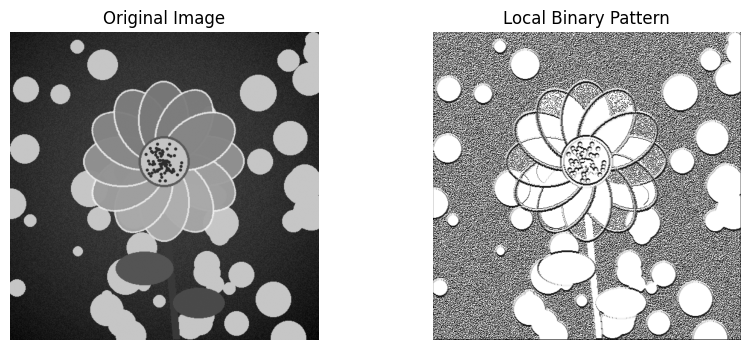

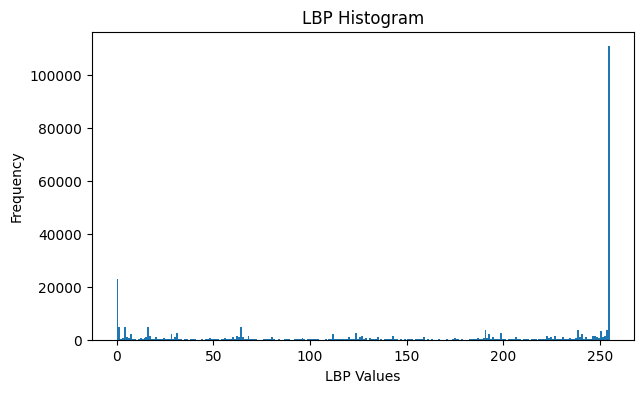

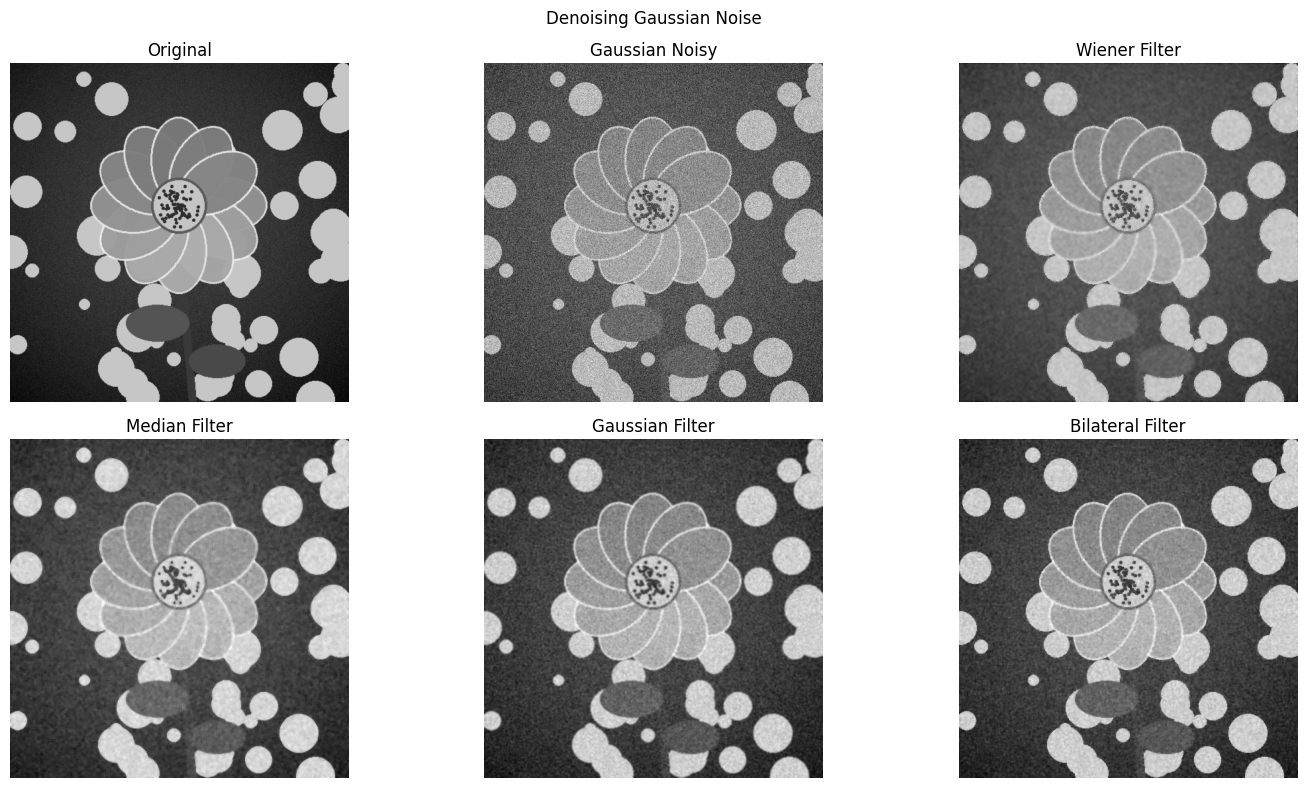

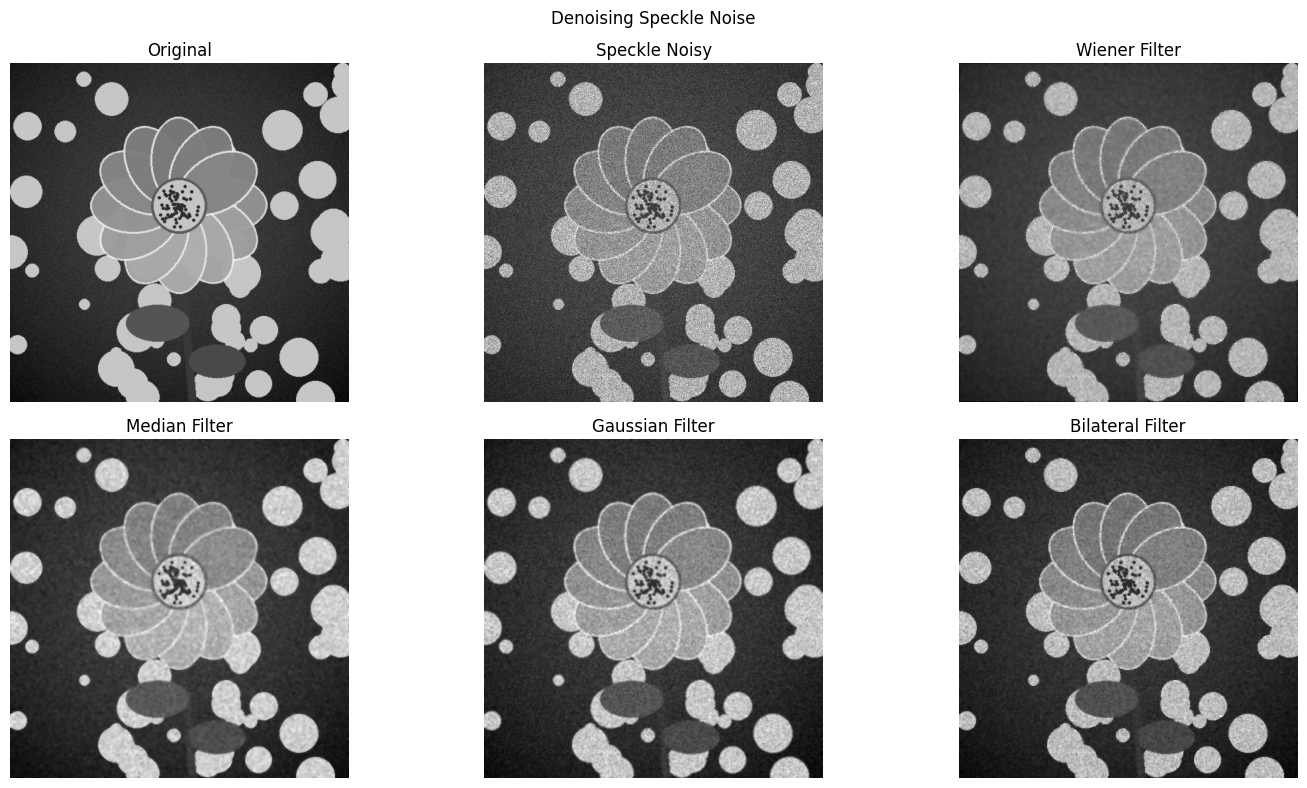

Assignment 9 completed successfully!


In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import wiener
from skimage.feature import local_binary_pattern



uploaded = files.upload()
filename = next(iter(uploaded))

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

img = img.astype(np.float32) / 255.0

original = (img * 255).astype(np.uint8)



P = 8
R = 1

lbp = local_binary_pattern(
    original, P, R, method='default'
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("Local Binary Pattern")
plt.axis("off")

plt.show()


plt.figure(figsize=(7, 4))
plt.hist(lbp.ravel(), bins=256)
plt.title("LBP Histogram")
plt.xlabel("LBP Values")
plt.ylabel("Frequency")
plt.show()




gaussian_noise = np.random.normal(
    0, 20, original.shape
)

gaussian_noisy = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)


speckle_noise = np.random.normal(
    0, 0.15, img.shape
)

speckle_noisy = np.clip(
    img + img * speckle_noise,
    0, 1
)

speckle_noisy = (speckle_noisy * 255).astype(np.uint8)



def apply_filters(noisy):


    wiener_result = wiener(
        noisy.astype(np.float32), (5, 5)
    )
    wiener_result = np.clip(
        wiener_result, 0, 255
    ).astype(np.uint8)


    median_result = cv2.medianBlur(noisy, 5)


    gaussian_result = cv2.GaussianBlur(
        noisy, (5, 5), 1.0
    )


    bilateral_result = cv2.bilateralFilter(
        noisy, 5, 50, 50
    )

    return (
        wiener_result,
        median_result,
        gaussian_result,
        bilateral_result
    )



gaussian_results = apply_filters(gaussian_noisy)
speckle_results = apply_filters(speckle_noisy)

filter_names = [
    "Wiener Filter",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter"
]


plt.figure(figsize=(15, 8))

images = [original, gaussian_noisy] + list(gaussian_results)
titles = ["Original", "Gaussian Noisy"] + filter_names

for i, image in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle("Denoising Gaussian Noise")
plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 8))

images = [original, speckle_noisy] + list(speckle_results)
titles = ["Original", "Speckle Noisy"] + filter_names

for i, image in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.suptitle("Denoising Speckle Noise")
plt.tight_layout()
plt.show()



cv2.imwrite("LBP_output.png",
            np.uint8(np.clip(lbp, 0, 255)))

cv2.imwrite("Gaussian_noisy.png", gaussian_noisy)
cv2.imwrite("Speckle_noisy.png", speckle_noisy)

for name, result in zip(filter_names, gaussian_results):
    cv2.imwrite("Gaussian_" + name.replace(" ", "_") + ".png", result)

for name, result in zip(filter_names, speckle_results):
    cv2.imwrite("Speckle_" + name.replace(" ", "_") + ".png", result)

print("Assignment 9 completed successfully!")
